In [1]:
import sys, json, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AI_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(AI_ROOT))

from recommender import (HybridRecommender, build_interactions, split_interactions,
                         evaluate, as_rec_fn, save_model, DEFAULT_MODEL_PATH)
from scripts.generate_vectors import ContentEmbedder, load_h5

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (7, 3.5)
K = 10

In [2]:
USE_FAKE = True  # True = skip Postgres and use data/fake/*.csv

def load_all():
    if not USE_FAKE:
        try:
            from api.dependencies import load_users, load_content, load_engagements
            return load_users(), load_content(), load_engagements(), "postgres"
        except Exception as e:
            print(f"DB not available ({type(e).__name__}), using fake CSVs")
    d = AI_ROOT / "data" / "fake"
    return (pd.read_csv(d / "users.csv"), pd.read_csv(d / "content.csv"),
            pd.read_csv(d / "engagements.csv"), "fake csv")

def parse(x):
    if isinstance(x, str):
        try:
            return json.loads(x)
        except json.JSONDecodeError:
            return x
    return x

users, content, eng, SOURCE = load_all()
users["preferences"] = users["preferences"].map(parse)
content["metadata"] = content["metadata"].map(parse)

# Vectors from Part 3 if present, otherwise build them here with the same code
try:
    ids, vectors, types = load_h5()
    print("vectors: loaded from models/vector_embeddings.h5")
except Exception as e:
    print(f"vectors: h5 not usable ({type(e).__name__}), computing in memory")
    vectors = ContentEmbedder().fit(content).transform(content)
    ids, types = content["id"].to_numpy(), content["type"].astype(str).tolist()

print(f"source={SOURCE} users={len(users)} content={len(content)} "
      f"engagements={len(eng)} vectors={vectors.shape}")

vectors: loaded from models/vector_embeddings.h5
source=fake csv users=300 content=1200 engagements=3938 vectors=(1200, 68)


In [3]:
inter = build_interactions(eng)
train_full, test = split_interactions(inter, test_frac=0.2, seed=42)   # test is never used for tuning
train, val = split_interactions(train_full, test_frac=0.2, seed=7)     # tune on val

for name, df in [("all", inter), ("train", train), ("val", val), ("test", test)]:
    print(f"{name:>5}: {len(df):>6} interactions, {df['userid'].nunique():>4} users")

  all:   3938 interactions,  274 users
train:   2573 interactions,  274 users
  val:    606 interactions,  216 users
 test:    759 interactions,  225 users


In [4]:
n_items = len(ids)

def fit(train_df, **params):
    return HybridRecommender(**params).fit(train_df, ids, vectors, types)

def compare(train_df, eval_df, **hybrid_params):
    # Pure baselines have no popularity or preference boosts, so each one is a fair comparison
    pop_model = fit(train_df)
    pure_content = fit(train_df, alpha=1.0, pop_weight=0, pref_boost=0)
    pure_cf = fit(train_df, alpha=0.0, pop_weight=0, pref_boost=0)
    hybrid = fit(train_df, **hybrid_params)
    ev = lambda fn: evaluate(fn, train_df, eval_df, users, n_items, K)
    return pd.DataFrame({
        "popularity":   ev(lambda i, p, k: pop_model.recommend_popular(i, k)),
        "content only": ev(as_rec_fn(pure_content)),
        "cf only":      ev(as_rec_fn(pure_cf)),
        "hybrid":       ev(as_rec_fn(hybrid)),
    }).T

compare(train, val).round(3)

,precision@10,recall@10,ndcg@10,hit_rate,coverage,users_evaluated
popularity,0.041,0.167,0.131,0.366,0.015,216.0
content only,0.006,0.017,0.013,0.046,0.757,216.0
cf only,0.012,0.058,0.033,0.111,0.258,216.0
hybrid,0.047,0.195,0.142,0.431,0.142,216.0


In [5]:
grid = list(itertools.product([0.3, 0.6, 0.8], [0.5, 1, 2, 4], [0.15, 0.5, 1.0]))
results = []
for alpha, pw, pb in grid:
    m = HybridRecommender(alpha=alpha, pop_weight=pw, pref_boost=pb).fit(train, ids, vectors, types)
    r = evaluate(as_rec_fn(m), train, val, users, n_items, K)
    results.append({"alpha": alpha, "pop_weight": pw, "pref_boost": pb, **r})

tuning = pd.DataFrame(results).sort_values(f"ndcg@{K}", ascending=False)
display(tuning.head(8).round(3))
best = tuning.iloc[0]
BEST = {"alpha": float(best["alpha"]), "pop_weight": float(best["pop_weight"]),
        "pref_boost": float(best["pref_boost"])}
print("best params:", BEST)

,alpha,pop_weight,pref_boost,precision@10,recall@10,ndcg@10,hit_rate,coverage,users_evaluated
11,0.3,4.0,1.0,0.056,0.233,0.170,0.468,0.049,216
23,0.6,4.0,1.0,0.055,0.227,0.169,0.468,0.058,216
35,0.8,4.0,1.0,0.054,0.224,0.165,0.468,0.066,216
22,0.6,4.0,0.5,0.054,0.225,0.165,0.454,0.043,216
10,0.3,4.0,0.5,0.053,0.228,0.163,0.449,0.035,216
7,0.3,2.0,0.5,0.052,0.215,0.161,0.454,0.072,216
34,0.8,4.0,0.5,0.053,0.218,0.159,0.444,0.051,216
8,0.3,2.0,1.0,0.050,0.205,0.157,0.444,0.080,216


best params: {'alpha': 0.3, 'pop_weight': 4.0, 'pref_boost': 1.0}


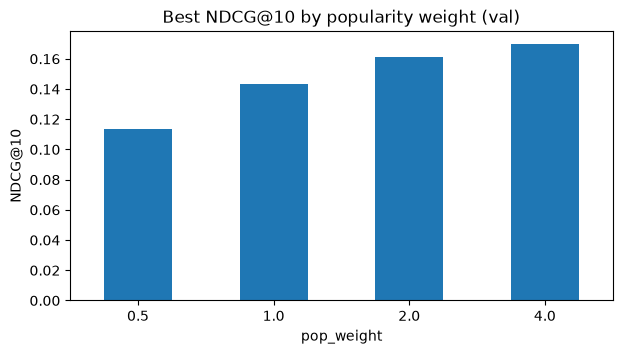

In [6]:
tuning.groupby("pop_weight")[f"ndcg@{K}"].max().plot.bar(rot=0, title="Best NDCG@10 by popularity weight (val)")
plt.ylabel("NDCG@10"); plt.show()

In [7]:
test_table = compare(train_full, test, **BEST)
display(test_table.round(3))

,precision@10,recall@10,ndcg@10,hit_rate,coverage,users_evaluated
popularity,0.052,0.176,0.137,0.422,0.017,225.0
content only,0.005,0.020,0.012,0.049,0.709,225.0
cf only,0.015,0.060,0.042,0.147,0.269,225.0
hybrid,0.074,0.267,0.223,0.560,0.058,225.0


In [8]:
model = HybridRecommender(**BEST).fit(inter, ids, vectors, types)
path = save_model(model)
print("saved ->", path)

# Smoke tests
uid = int(inter["userid"].value_counts().index[0])
hist = dict(zip(*inter.loc[inter["userid"] == uid, ["contentid", "score"]].T.values))
prefs = users.set_index("id")["preferences"].get(uid)
print("warm user", uid, model.recommend(hist, prefs, k=5))
print("new user  ", model.recommend({}, ["art"], k=5))

saved -> C:\Users\Mohit\OneDrive\Desktop\Illusion-Gallery\ai\models\recommendation_v1.pkl
warm user 259 {'algoType': 'hybrid', 'items': [{'contentId': 731, 'score': 4.958959579467773}, {'contentId': 695, 'score': 4.504778861999512}, {'contentId': 333, 'score': 3.9285547733306885}, {'contentId': 192, 'score': 3.8572869300842285}, {'contentId': 1180, 'score': 3.7667465209960938}]}
new user   {'algoType': 'cold_start', 'items': [{'contentId': 731, 'score': 1.424468755722046}, {'contentId': 897, 'score': 1.4232041835784912}, {'contentId': 196, 'score': 1.32080078125}, {'contentId': 695, 'score': 1.3163368701934814}, {'contentId': 452, 'score': 1.281656265258789}]}
